In [306]:
# Phase 8 — AQI Analysis
# Cell 1: Imports and dataset loading

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Load the selected-features dataset
file_path = "../data/processed/Ambazari_Nagpur_Selected_Features_Dataset_2024_2025.csv"

aqi_data = pd.read_csv(file_path)

# Parse timestamps
aqi_data["timestamp"] = pd.to_datetime(aqi_data["timestamp"])

print("Dataset loaded successfully.")
print("Shape:", aqi_data.shape)
print("Date range:", aqi_data["timestamp"].min(), "to", aqi_data["timestamp"].max())
print("Columns:", aqi_data.columns.tolist())

Dataset loaded successfully.
Shape: (17519, 46)
Date range: 2024-01-02 00:00:00 to 2025-12-31 22:00:00
Columns: ['timestamp', 'pm25', 'pm10', 'no2', 'so2', 'co', 'o3', 'temperature', 'humidity', 'wind_speed', 'weather_code', 'hour_sin', 'hour_cos', 'month_sin', 'month_cos', 'wind_direction_sin', 'wind_direction_cos', 'season', 'pm25_lag_1', 'pm25_lag_3', 'pm25_lag_6', 'pm25_lag_12', 'pm25_lag_24', 'pm10_lag_1', 'pm10_lag_24', 'no2_lag_1', 'no2_lag_24', 'so2_lag_1', 'co_lag_1', 'o3_lag_1', 'o3_lag_24', 'pm25_rolling_mean_3', 'pm25_rolling_mean_6', 'pm25_rolling_mean_12', 'pm25_rolling_mean_24', 'pm10_rolling_mean_3', 'pm10_rolling_mean_6', 'pm10_rolling_mean_24', 'no2_rolling_mean_3', 'o3_rolling_mean_3', 'target_pm25', 'target_pm10', 'target_no2', 'target_so2', 'target_co', 'target_o3']


In [307]:
# Cell 2: Data validation

pollutants = ["pm25", "pm10", "no2", "so2", "co", "o3"]

# Check timestamps
aqi_data = aqi_data.sort_values("timestamp").reset_index(drop=True)

print("Duplicate timestamps:", aqi_data["timestamp"].duplicated().sum())

time_gaps = aqi_data["timestamp"].diff()
print("Gaps greater than 1 hour:",
      (time_gaps > pd.Timedelta(hours=1)).sum())

# Check pollutant data
print("\nMissing pollutant values:")
display(aqi_data[pollutants].isna().sum())

print("\nPollutant summary:")
display(aqi_data[pollutants].describe().round(3))

print("\nNegative pollutant values:")
display((aqi_data[pollutants] < 0).sum())

Duplicate timestamps: 0
Gaps greater than 1 hour: 0

Missing pollutant values:


pm25    0
pm10    0
no2     0
so2     0
co      0
o3      0
dtype: int64


Pollutant summary:


,pm25,pm10,no2,so2,co,o3
count,17519.000,17519.000,17519.000,17519.000,17519.000,17519.000
mean,46.215,91.284,21.054,16.950,0.645,35.942
std,27.094,46.002,19.183,18.081,0.541,32.438
min,0.050,6.190,0.010,0.020,0.000,0.000
25%,24.650,56.600,9.020,8.110,0.330,9.860
50%,42.000,86.380,15.160,11.860,0.480,25.970
75%,63.270,117.550,25.550,18.295,0.730,53.260
max,487.480,832.540,177.750,198.760,7.630,187.860



Negative pollutant values:


pm25    0
pm10    0
no2     0
so2     0
co      0
o3      0
dtype: int64

In [308]:
# Cell 3: CPCB pollutant averaging requirements

# Based on the averaging periods specified in About_AQI.pdf
pollutant_averaging = {
    "pm25": 24,
    "pm10": 24,
    "no2": 24,
    "so2": 24,
    "co": 8,
    "o3": 8
}

print("Pollutant averaging periods:")
for pollutant, hours in pollutant_averaging.items():
    print(f"{pollutant.upper():5} -> {hours}-hour average")

Pollutant averaging periods:
PM25  -> 24-hour average
PM10  -> 24-hour average
NO2   -> 24-hour average
SO2   -> 24-hour average
CO    -> 8-hour average
O3    -> 8-hour average


In [309]:
# Cell 4: Calculate pollutant rolling averages

# CPCB averaging periods:
# PM2.5, PM10, NO2, SO2 -> 24 hours
# CO, O3 -> 8 hours

for pollutant in ["pm25", "pm10", "no2", "so2"]:
    aqi_data[f"{pollutant}_avg"] = (
        aqi_data[pollutant]
        .rolling(window=24, min_periods=24)
        .mean()
    )

for pollutant in ["co", "o3"]:
    aqi_data[f"{pollutant}_avg"] = (
        aqi_data[pollutant]
        .rolling(window=8, min_periods=8)
        .mean()
    )

average_columns = [f"{p}_avg" for p in pollutants]

print("Rolling averages created.")
display(aqi_data[average_columns].isna().sum().to_frame("Missing averages"))
display(aqi_data[average_columns].head(27))

Rolling averages created.


,Missing averages
pm25_avg,23
pm10_avg,23
no2_avg,23
so2_avg,23
co_avg,7
o3_avg,7


,pm25_avg,pm10_avg,no2_avg,so2_avg,co_avg,o3_avg
0,NaN,NaN,NaN,NaN,NaN,NaN
1,NaN,NaN,NaN,NaN,NaN,NaN
2,NaN,NaN,NaN,NaN,NaN,NaN
3,NaN,NaN,NaN,NaN,NaN,NaN
4,NaN,NaN,NaN,NaN,NaN,NaN
5,NaN,NaN,NaN,NaN,NaN,NaN
6,NaN,NaN,NaN,NaN,NaN,NaN
7,NaN,NaN,NaN,NaN,1.44500,7.09625
8,NaN,NaN,NaN,NaN,1.33125,9.03250
9,NaN,NaN,NaN,NaN,1.22875,15.75000


In [310]:
# Cell 5: CPCB concentration and AQI intervals

aqi_intervals = {
    "pm25": [
        (0, 30, 0, 50),
        (30, 60, 50, 100),
        (60, 90, 100, 200),
        (90, 120, 200, 300),
        (120, 250, 300, 400)
    ],
    "pm10": [
        (0, 50, 0, 50),
        (50, 100, 50, 100),
        (100, 250, 100, 200),
        (250, 350, 200, 300),
        (350, 430, 300, 400)
    ],
    "no2": [
        (0, 40, 0, 50),
        (40, 80, 50, 100),
        (80, 180, 100, 200),
        (180, 280, 200, 300),
        (280, 400, 300, 400)
    ],
    "so2": [
        (0, 40, 0, 50),
        (40, 80, 50, 100),
        (80, 380, 100, 200),
        (380, 800, 200, 300),
        (800, 1600, 300, 400)
    ],
    "co": [
        (0, 1.0, 0, 50),
        (1.0, 2.0, 50, 100),
        (2.0, 10.0, 100, 200),
        (10.0, 17.0, 200, 300),
        (17.0, 34.0, 300, 400)
    ],
    "o3": [
        (0, 50, 0, 50),
        (50, 100, 50, 100),
        (100, 168, 100, 200),
        (168, 208, 200, 300),
        (208, 748, 300, 400)
    ]
}

print("Continuous concentration intervals defined.")

Continuous concentration intervals defined.


In [311]:
# Cell 6: Calculate pollutant sub-index

def calculate_sub_index(concentration, pollutant):
    if pd.isna(concentration) or concentration < 0:
        return np.nan

    intervals = aqi_intervals[pollutant]

    for c_lo, c_hi, aqi_lo, aqi_hi in intervals:
        if c_lo <= concentration <= c_hi:
            value = aqi_lo + (
                (concentration - c_lo) / (c_hi - c_lo)
            ) * (aqi_hi - aqi_lo)

            return int(np.floor(value))

    return np.nan

print("Sub-index function updated.")

Sub-index function updated.


In [312]:
# Cell 7: Validate against CPCB examples from About_AQI.pdf

tests = [
    ("pm25", 31, 51),
    ("pm25", 60, 100),
    ("pm25", 45, 75)
]

for pollutant, concentration, expected in tests:
    actual = calculate_sub_index(concentration, pollutant)
    passed = actual == expected

    print(
        f"{pollutant.upper()} at {concentration}: "
        f"expected={expected}, actual={actual}, pass={passed}"
    )

PM25 at 31: expected=51, actual=51, pass=True
PM25 at 60: expected=100, actual=100, pass=True
PM25 at 45: expected=75, actual=75, pass=True


In [313]:
# Cell 8: Test AQI interval boundaries

for pollutant, intervals in aqi_intervals.items():
    print(f"\n{pollutant.upper()}")

    for c_lo, c_hi, aqi_lo, aqi_hi in intervals:
        lower_result = calculate_sub_index(c_lo, pollutant)
        upper_result = calculate_sub_index(c_hi, pollutant)

        print(
            f"{c_lo}–{c_hi}: "
            f"lower AQI={lower_result}, "
            f"upper AQI={upper_result}"
        )


PM25
0–30: lower AQI=0, upper AQI=50
30–60: lower AQI=50, upper AQI=100
60–90: lower AQI=100, upper AQI=200
90–120: lower AQI=200, upper AQI=300
120–250: lower AQI=300, upper AQI=400

PM10
0–50: lower AQI=0, upper AQI=50
50–100: lower AQI=50, upper AQI=100
100–250: lower AQI=100, upper AQI=200
250–350: lower AQI=200, upper AQI=300
350–430: lower AQI=300, upper AQI=400

NO2
0–40: lower AQI=0, upper AQI=50
40–80: lower AQI=50, upper AQI=100
80–180: lower AQI=100, upper AQI=200
180–280: lower AQI=200, upper AQI=300
280–400: lower AQI=300, upper AQI=400

SO2
0–40: lower AQI=0, upper AQI=50
40–80: lower AQI=50, upper AQI=100
80–380: lower AQI=100, upper AQI=200
380–800: lower AQI=200, upper AQI=300
800–1600: lower AQI=300, upper AQI=400

CO
0–1.0: lower AQI=0, upper AQI=50
1.0–2.0: lower AQI=50, upper AQI=100
2.0–10.0: lower AQI=100, upper AQI=200
10.0–17.0: lower AQI=200, upper AQI=300
17.0–34.0: lower AQI=300, upper AQI=400

O3
0–50: lower AQI=0, upper AQI=50
50–100: lower AQI=50, upper 

In [314]:
# Cell 9: Recalculate pollutant sub-indices

for pollutant in pollutants:
    aqi_data[f"{pollutant}_sub_index"] = (
        aqi_data[f"{pollutant}_avg"].apply(
            lambda value: calculate_sub_index(value, pollutant)
        )
    )

sub_index_columns = [f"{p}_sub_index" for p in pollutants]

print("Sub-indices recalculated.")
print("\nMissing sub-index values:")
display(aqi_data[sub_index_columns].isna().sum().to_frame("Missing"))

Sub-indices recalculated.

Missing sub-index values:


,Missing
pm25_sub_index,23
pm10_sub_index,23
no2_sub_index,23
so2_sub_index,23
co_sub_index,7
o3_sub_index,7


In [315]:
# Cell 10: Check concentrations beyond defined intervals

for pollutant in pollutants:
    avg_col = f"{pollutant}_avg"
    intervals = aqi_intervals[pollutant]
    max_concentration = max(interval[1] for interval in intervals)

    above_limit = (
        aqi_data[avg_col].notna()
        & (aqi_data[avg_col] > max_concentration)
    ).sum()

    print(
        f"{pollutant.upper():5} — "
        f"Above final interval: {above_limit}"
    )

PM25  — Above final interval: 0
PM10  — Above final interval: 0
NO2   — Above final interval: 0
SO2   — Above final interval: 0
CO    — Above final interval: 0
O3    — Above final interval: 0


In [316]:
# Cell 11: Recalculate overall AQI

sub_index_columns = [f"{p}_sub_index" for p in pollutants]

aqi_data["AQI"] = aqi_data[sub_index_columns].max(
    axis=1,
    skipna=False
)

print("Overall AQI recalculated.")
print("Missing AQI values:", aqi_data["AQI"].isna().sum())
print("Minimum AQI:", aqi_data["AQI"].min())
print("Maximum AQI:", aqi_data["AQI"].max())

Overall AQI recalculated.
Missing AQI values: 23
Minimum AQI: 22.0
Maximum AQI: 307.0


In [317]:
# Cell 12: Recalculate AQI categories

def classify_aqi(aqi):
    if pd.isna(aqi):
        return np.nan
    elif aqi <= 50:
        return "Good"
    elif aqi <= 100:
        return "Satisfactory"
    elif aqi <= 200:
        return "Moderate"
    elif aqi <= 300:
        return "Poor"
    elif aqi <= 400:
        return "Very Poor"
    else:
        return "Severe"

aqi_data["AQI_Category"] = aqi_data["AQI"].apply(classify_aqi)

print("AQI categories recalculated.")
display(aqi_data["AQI_Category"].value_counts(dropna=False).to_frame("Record Count"))

AQI categories recalculated.


,Record Count
AQI_Category,
Satisfactory,7262
Moderate,6535
Good,3004
Poor,683
NaN,23
Very Poor,12


In [318]:
# Cell 24: Final AQI validation

aqi_data["year"] = pd.to_datetime(aqi_data["timestamp"]).dt.year

print("Total records:", len(aqi_data))
print("Valid AQI records:", aqi_data["AQI"].notna().sum())
print("Missing AQI records:", aqi_data["AQI"].isna().sum())

print("\nAQI range:")
print("Minimum:", aqi_data["AQI"].min())
print("Maximum:", aqi_data["AQI"].max())

print("\nAQI category distribution:")
display(
    aqi_data["AQI_Category"]
    .value_counts(dropna=False)
    .to_frame("Record Count")
)

print("\nAverage AQI by year:")
display(
    aqi_data.groupby("year")["AQI"]
    .mean()
    .round(2)
    .to_frame("Average AQI")
)

Total records: 17519
Valid AQI records: 17496
Missing AQI records: 23

AQI range:
Minimum: 22.0
Maximum: 307.0

AQI category distribution:


,Record Count
AQI_Category,
Satisfactory,7262
Moderate,6535
Good,3004
Poor,683
NaN,23
Very Poor,12



Average AQI by year:


,Average AQI
year,
2024,104.27
2025,89.19


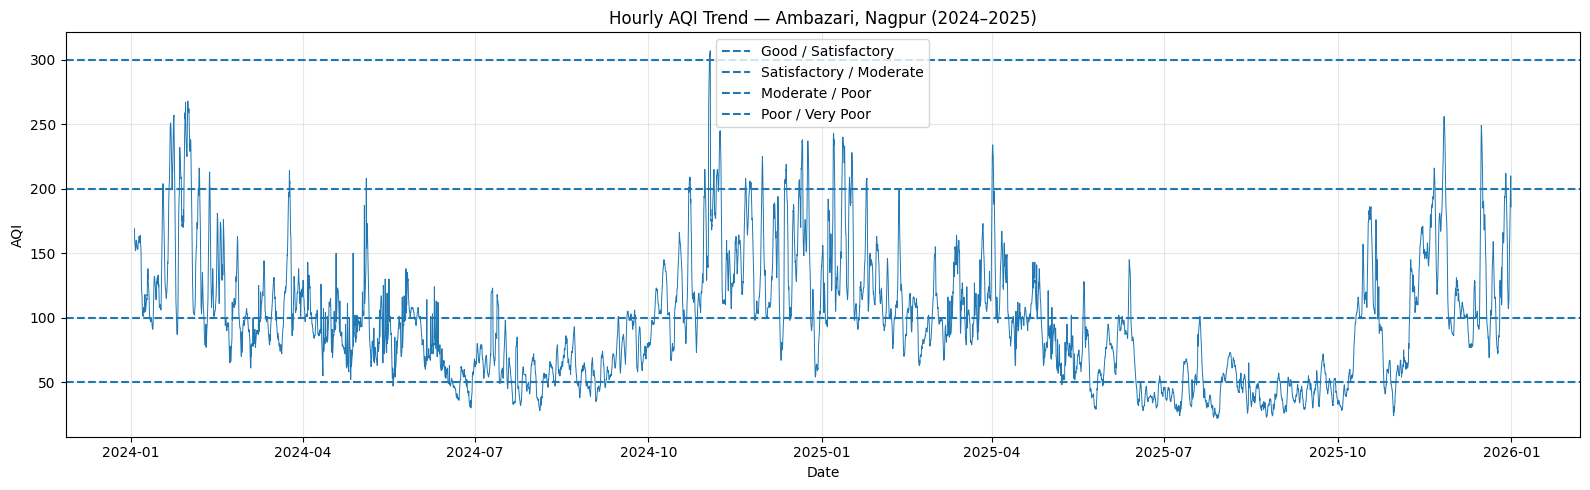

In [319]:
# Cell 14: AQI over time

plt.figure(figsize=(16, 5))

plt.plot(
    aqi_data["timestamp"],
    aqi_data["AQI"],
    linewidth=0.7
)

plt.axhline(50, linestyle="--", label="Good / Satisfactory")
plt.axhline(100, linestyle="--", label="Satisfactory / Moderate")
plt.axhline(200, linestyle="--", label="Moderate / Poor")
plt.axhline(300, linestyle="--", label="Poor / Very Poor")

plt.title("Hourly AQI Trend — Ambazari, Nagpur (2024–2025)")
plt.xlabel("Date")
plt.ylabel("AQI")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

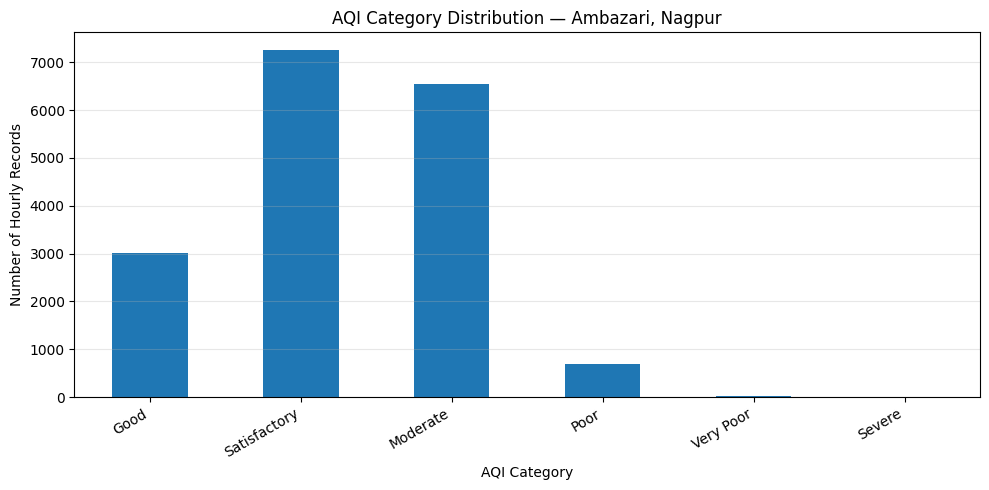

,Record Count
AQI_Category,
Good,3004
Satisfactory,7262
Moderate,6535
Poor,683
Very Poor,12
Severe,0


In [320]:
# Cell 15: AQI category distribution

category_order = [
    "Good",
    "Satisfactory",
    "Moderate",
    "Poor",
    "Very Poor",
    "Severe"
]

category_counts = (
    aqi_data["AQI_Category"]
    .value_counts()
    .reindex(category_order, fill_value=0)
)

plt.figure(figsize=(10, 5))
category_counts.plot(kind="bar")

plt.title("AQI Category Distribution — Ambazari, Nagpur")
plt.xlabel("AQI Category")
plt.ylabel("Number of Hourly Records")
plt.xticks(rotation=30, ha="right")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

display(category_counts.to_frame("Record Count"))

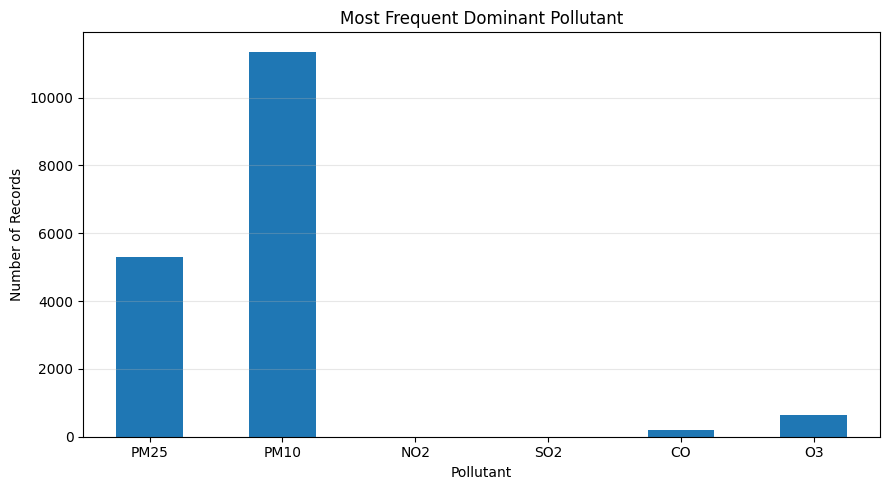

,Dominant Record Count
PM25,5295
PM10,11354
NO2,0
SO2,0
CO,212
O3,651


In [321]:
# Cell 16: Identify the dominant pollutant

sub_index_columns = [f"{p}_sub_index" for p in pollutants]

valid_sub_indices = aqi_data[sub_index_columns].dropna(how="all")

dominant_pollutant = (
    valid_sub_indices
    .idxmax(axis=1)
    .str.replace("_sub_index", "", regex=False)
)

dominant_counts = (
    dominant_pollutant
    .value_counts()
    .reindex(pollutants, fill_value=0)
)

dominant_counts.index = dominant_counts.index.str.upper()

dominant_counts.plot(kind="bar", figsize=(9, 5))

plt.title("Most Frequent Dominant Pollutant")
plt.xlabel("Pollutant")
plt.ylabel("Number of Records")
plt.xticks(rotation=0)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

display(dominant_counts.to_frame("Dominant Record Count"))

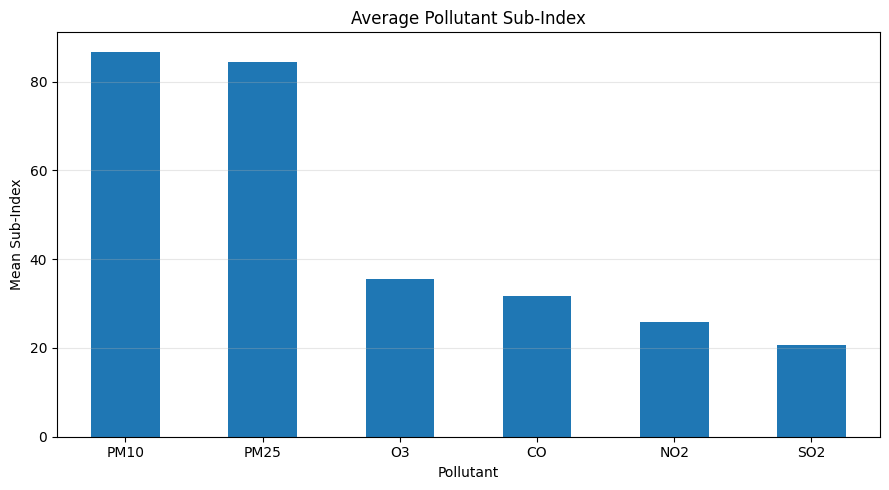

,Mean Sub-Index
PM10,86.77
PM25,84.35
O3,35.58
CO,31.63
NO2,25.79
SO2,20.67


In [322]:
# Cell 17: Compare average pollutant sub-indices

mean_sub_indices = aqi_data[sub_index_columns].mean().sort_values(
    ascending=False
)

mean_sub_indices.index = (
    mean_sub_indices.index
    .str.replace("_sub_index", "", regex=False)
    .str.upper()
)

mean_sub_indices.plot(kind="bar", figsize=(9, 5))

plt.title("Average Pollutant Sub-Index")
plt.xlabel("Pollutant")
plt.ylabel("Mean Sub-Index")
plt.xticks(rotation=0)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

display(mean_sub_indices.to_frame("Mean Sub-Index").round(2))

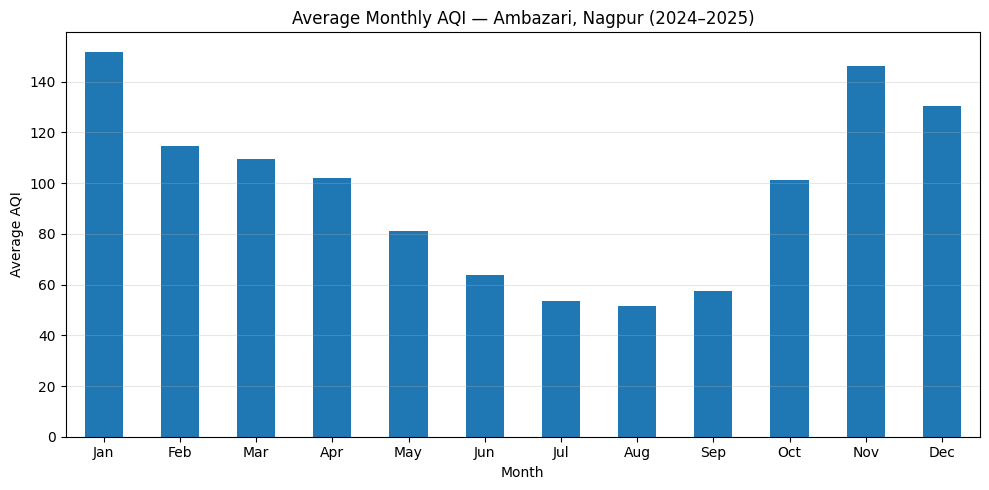

,Average AQI
Jan,151.91
Feb,114.68
Mar,109.47
Apr,102.02
May,81.23
Jun,63.61
Jul,53.56
Aug,51.41
Sep,57.44
Oct,101.37


In [323]:
# Cell 18: Monthly AQI analysis

aqi_data["month"] = aqi_data["timestamp"].dt.month

monthly_aqi = (
    aqi_data.groupby("month")["AQI"]
    .mean()
    .reindex(range(1, 13))
)

month_names = [
    "Jan", "Feb", "Mar", "Apr", "May", "Jun",
    "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"
]

monthly_aqi.index = month_names

monthly_aqi.plot(kind="bar", figsize=(10, 5))

plt.title("Average Monthly AQI — Ambazari, Nagpur (2024–2025)")
plt.xlabel("Month")
plt.ylabel("Average AQI")
plt.xticks(rotation=0)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

display(monthly_aqi.to_frame("Average AQI").round(2))

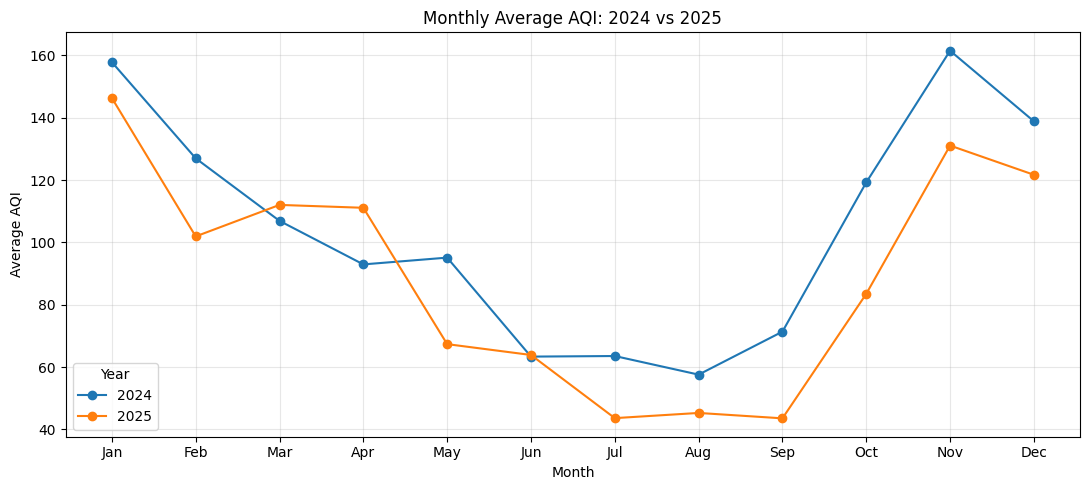

year,2024,2025
Jan,157.86,146.35
Feb,126.99,101.92
Mar,106.91,112.03
Apr,92.94,111.11
May,95.11,67.35
Jun,63.34,63.87
Jul,63.53,43.60
Aug,57.56,45.26
Sep,71.36,43.53
Oct,119.25,83.49


In [324]:
# Cell 19: Monthly AQI comparison by year

aqi_data["year"] = aqi_data["timestamp"].dt.year
aqi_data["month_num"] = aqi_data["timestamp"].dt.month

monthly_yearly_aqi = aqi_data.pivot_table(
    index="month_num",
    columns="year",
    values="AQI",
    aggfunc="mean"
).reindex(range(1, 13))

monthly_yearly_aqi.index = month_names

monthly_yearly_aqi.plot(
    kind="line",
    marker="o",
    figsize=(11, 5)
)

plt.title("Monthly Average AQI: 2024 vs 2025")
plt.xlabel("Month")
plt.ylabel("Average AQI")
plt.xticks(range(12), month_names)
plt.grid(alpha=0.3)
plt.legend(title="Year")
plt.tight_layout()
plt.show()

display(monthly_yearly_aqi.round(2))

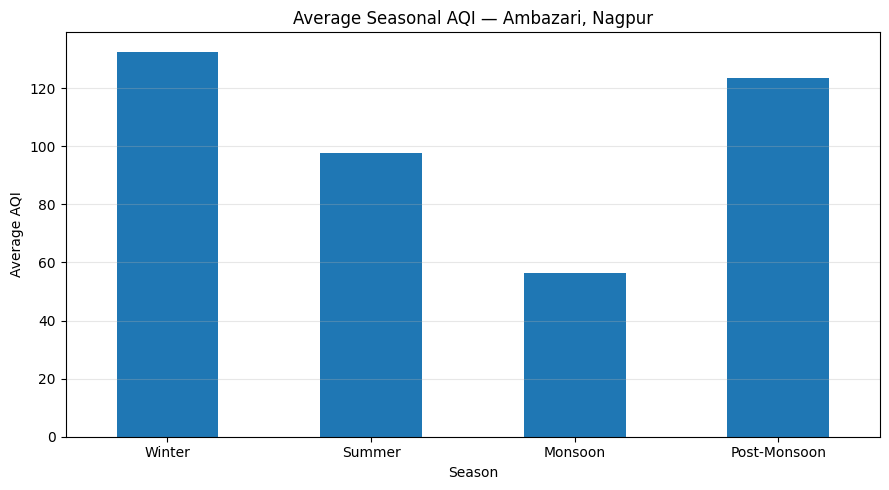

,Average AQI
season,
Winter,132.57
Summer,97.53
Monsoon,56.44
Post-Monsoon,123.47


In [325]:
# Cell 20: Seasonal AQI analysis

season_map = {
    12: "Winter",
    1: "Winter",
    2: "Winter",
    3: "Summer",
    4: "Summer",
    5: "Summer",
    6: "Monsoon",
    7: "Monsoon",
    8: "Monsoon",
    9: "Monsoon",
    10: "Post-Monsoon",
    11: "Post-Monsoon"
}

aqi_data["season"] = aqi_data["timestamp"].dt.month.map(season_map)

season_order = [
    "Winter",
    "Summer",
    "Monsoon",
    "Post-Monsoon"
]

seasonal_aqi = (
    aqi_data.groupby("season")["AQI"]
    .mean()
    .reindex(season_order)
)

seasonal_aqi.plot(kind="bar", figsize=(9, 5))

plt.title("Average Seasonal AQI — Ambazari, Nagpur")
plt.xlabel("Season")
plt.ylabel("Average AQI")
plt.xticks(rotation=0)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

display(seasonal_aqi.to_frame("Average AQI").round(2))

,Record Count,Percentage (%)
AQI_Category,,
Good,3004,17.17
Satisfactory,7262,41.51
Moderate,6535,37.35
Poor,683,3.90
Very Poor,12,0.07
Severe,0,0.00


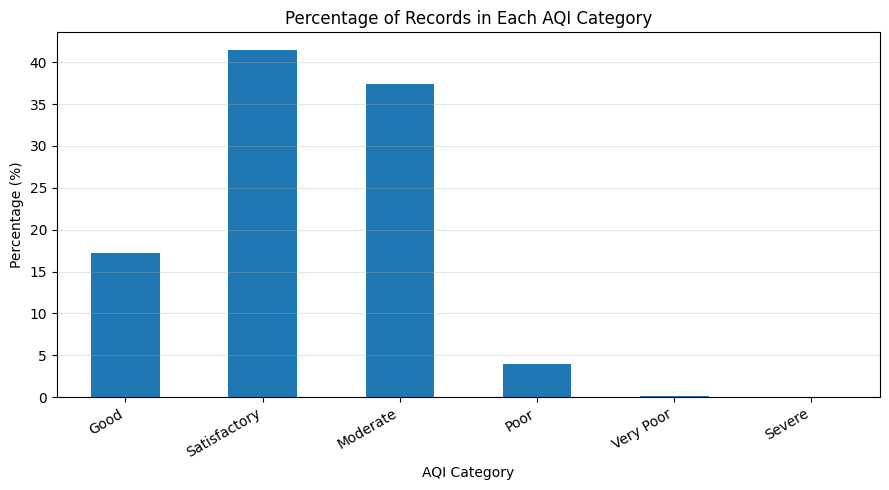

In [326]:
# Cell 21: AQI category percentages

category_counts = aqi_data["AQI_Category"].value_counts()
category_percentages = (
    aqi_data["AQI_Category"]
    .value_counts(normalize=True)
    .reindex(category_order, fill_value=0) * 100
)

category_summary = pd.DataFrame({
    "Record Count": category_counts.reindex(category_order, fill_value=0),
    "Percentage (%)": category_percentages.round(2)
})

display(category_summary)

category_percentages.plot(
    kind="bar",
    figsize=(9, 5)
)

plt.title("Percentage of Records in Each AQI Category")
plt.xlabel("AQI Category")
plt.ylabel("Percentage (%)")
plt.xticks(rotation=30, ha="right")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

In [327]:
# Cell 22: Dominant pollutant percentages

valid_sub_indices = aqi_data[sub_index_columns].dropna(how="all")

dominant_pollutant = valid_sub_indices.idxmax(axis=1)

dominant_counts = (
    dominant_pollutant
    .value_counts()
    .reindex(sub_index_columns, fill_value=0)
)

dominant_summary = pd.DataFrame({
    "Record Count": dominant_counts,
    "Percentage (%)": (
        dominant_counts / len(valid_sub_indices) * 100
    ).round(2)
})

dominant_summary.index = (
    dominant_summary.index
    .str.replace("_sub_index", "", regex=False)
    .str.upper()
)

display(dominant_summary.sort_values("Record Count", ascending=False))

,Record Count,Percentage (%)
PM10,11354,64.84
PM25,5295,30.24
O3,651,3.72
CO,212,1.21
SO2,0,0.00
NO2,0,0.00


In [328]:
# Cell 23: Final AQI validation summary

print("AQI ANALYSIS VALIDATION")
print("-" * 40)

print("Total records:", len(aqi_data))
print("Valid AQI records:", aqi_data["AQI"].notna().sum())
print("Missing AQI records:", aqi_data["AQI"].isna().sum())

print("\nAQI range:")
print("Minimum:", aqi_data["AQI"].min())
print("Maximum:", aqi_data["AQI"].max())

print("\nAQI outside 0–500:",
      ((aqi_data["AQI"] < 0) | (aqi_data["AQI"] > 500)).sum())

print("\nMissing values in pollutant sub-indices:")
display(aqi_data[sub_index_columns].isna().sum().to_frame("Missing"))

print("\nAQI category counts:")
display(
    aqi_data["AQI_Category"]
    .value_counts(dropna=False)
    .to_frame("Record Count")
)

print("\nAverage AQI by year:")
display(
    aqi_data.groupby("year")["AQI"]
    .mean()
    .round(2)
    .to_frame("Average AQI")
)

AQI ANALYSIS VALIDATION
----------------------------------------
Total records: 17519
Valid AQI records: 17496
Missing AQI records: 23

AQI range:
Minimum: 22.0
Maximum: 307.0

AQI outside 0–500: 0

Missing values in pollutant sub-indices:


,Missing
pm25_sub_index,23
pm10_sub_index,23
no2_sub_index,23
so2_sub_index,23
co_sub_index,7
o3_sub_index,7



AQI category counts:


,Record Count
AQI_Category,
Satisfactory,7262
Moderate,6535
Good,3004
Poor,683
NaN,23
Very Poor,12



Average AQI by year:


,Average AQI
year,
2024,104.27
2025,89.19


In [329]:
# Cell 25: Check shared interval boundaries

for pollutant, intervals in aqi_intervals.items():
    print(f"\n{pollutant.upper()}")

    for i in range(len(intervals) - 1):
        boundary = intervals[i][1]

        left_aqi = intervals[i][3]
        right_aqi = intervals[i + 1][2]
        actual_aqi = calculate_sub_index(boundary, pollutant)

        print(
            f"Boundary {boundary}: "
            f"left AQI={left_aqi}, "
            f"right AQI={right_aqi}, "
            f"actual={actual_aqi}"
        )


PM25
Boundary 30: left AQI=50, right AQI=50, actual=50
Boundary 60: left AQI=100, right AQI=100, actual=100
Boundary 90: left AQI=200, right AQI=200, actual=200
Boundary 120: left AQI=300, right AQI=300, actual=300

PM10
Boundary 50: left AQI=50, right AQI=50, actual=50
Boundary 100: left AQI=100, right AQI=100, actual=100
Boundary 250: left AQI=200, right AQI=200, actual=200
Boundary 350: left AQI=300, right AQI=300, actual=300

NO2
Boundary 40: left AQI=50, right AQI=50, actual=50
Boundary 80: left AQI=100, right AQI=100, actual=100
Boundary 180: left AQI=200, right AQI=200, actual=200
Boundary 280: left AQI=300, right AQI=300, actual=300

SO2
Boundary 40: left AQI=50, right AQI=50, actual=50
Boundary 80: left AQI=100, right AQI=100, actual=100
Boundary 380: left AQI=200, right AQI=200, actual=200
Boundary 800: left AQI=300, right AQI=300, actual=300

CO
Boundary 1.0: left AQI=50, right AQI=50, actual=50
Boundary 2.0: left AQI=100, right AQI=100, actual=100
Boundary 10.0: left AQI=2

In [330]:

from pathlib import Path

output_path = Path(
    "../data/processed/Ambazari_Nagpur_AQI_Analysis_2024_2025.csv"
)

aqi_data.to_csv(output_path, index=False)

print("AQI dataset exported successfully.")
print("Saved to:", output_path.resolve())
print("Dataset shape:", aqi_data.shape)
print("AQI column available:", "AQI" in aqi_data.columns)
print("AQI category available:", "AQI_Category" in aqi_data.columns)


AQI dataset exported successfully.
Saved to: C:\Users\ASUS\Documents\DHV MINI\data\processed\Ambazari_Nagpur_AQI_Analysis_2024_2025.csv
Dataset shape: (17519, 63)
AQI column available: True
AQI category available: True
